In [ ]:
import random
from collections import deque

import gymnasium as gym
from gymnasium import spaces
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm.auto import trange




class FinalKitchenEnv(gym.Env):
    """원본 Kitchen 환경을 4주문과 확장 레시피에 맞춰 일반화한다."""
    def __init__(self, stage=2):
        super().__init__()
        if stage not in (2, 3):
            raise ValueError("stage는 2 또는 3입니다.")
        self.stage = stage
        self.ingredient_count = 3 if stage == 2 else 5
        self.menu_count = 2 if stage == 2 else 4
        self.min_time, self.max_time = 6, 16
        self.recipes = [(0, 1), (0, 1, 2)]
        if stage == 3:
            self.recipes += [(0, 1, 3), (0, 1, 2, 3, 4)]
        self.serve_action = self.ingredient_count + 1
        self.action_space = spaces.Discrete(self.ingredient_count + 2)
        self.state_shape = (2,) * self.ingredient_count + (self.menu_count + 1, 17) * 4
        self.observation_space = spaces.Discrete(int(np.prod(self.state_shape)))
        self.scale = np.array(
            [1] * self.ingredient_count + [self.menu_count, self.max_time] * 4,
            dtype=np.float32
        )
        self.action_names = ["대기", "도우", "치즈", "페퍼로니"]
        if stage == 3:
            self.action_names += ["버섯", "올리브"]
        self.action_names += ["서빙"]
        self.finished = True

    def _get_obs_to_id(self):
        state = self.ingredients + [value for order in self.orders for value in order]
        return int(np.ravel_multi_index(tuple(state), self.state_shape))

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        orders = options.get("orders") if options else None
        if orders is None:
            orders = [
                (random.randint(1, self.menu_count),
                 random.randint(self.min_time, self.max_time))
                for _ in range(4)
            ]
        orders = list(orders)
        if len(orders) != 4 or any(
            menu not in range(1, self.menu_count + 1)
            or timer not in range(self.min_time, self.max_time + 1)
            for menu, timer in orders
        ):
            raise ValueError("메뉴 범위와 제한 시간 6~16인 주문 4개가 필요합니다.")
        self.orders = orders.copy()
        self.ingredients = [0] * self.ingredient_count
        self.sequence = []
        self.finished = False
        return self._get_obs_to_id(), {}

    def step(self, action):
        if self.finished:
            raise RuntimeError("reset() 후 실행하세요.")
        if not self.action_space.contains(action):
            raise ValueError("행동 번호가 범위를 벗어났습니다.")
        reward = -0.1
        served = expired = invalid = wrong_serve = 0

        if action == self.serve_action:
            menu = next(
                (i + 1 for i, recipe in enumerate(self.recipes)
                 if tuple(self.sequence) == recipe), 0
            )
            for slot, (ordered_menu, _) in enumerate(self.orders):
                if menu != 0 and ordered_menu == menu:
                    self.orders[slot] = (0, 0)
                    served = 1
                    break
            reward += 20 if served else -15
            wrong_serve = 1 - served
            self.ingredients = [0] * self.ingredient_count
            self.sequence = []
        elif action != 0:
            ingredient = int(action) - 1
            candidate = tuple(self.sequence + [ingredient])
            # 추가 후 순서가 적어도 한 레시피의 앞부분과 같아야 한다.
            # 도우→치즈→버섯과 도우→치즈→페퍼로니→버섯을 모두 지원한다.
            allowed = any(
                candidate == recipe[:len(candidate)]
                for recipe in self.recipes
            )
            if self.ingredients[ingredient] or not allowed:
                reward -= 2
                invalid = 1
            else:
                self.ingredients[ingredient] = 1
                self.sequence.append(ingredient)

        for slot, (menu, timer) in enumerate(self.orders):
            if menu == 0:
                continue
            if timer == 1:
                self.orders[slot] = (0, 0)
                expired += 1
                reward -= 10
            else:
                self.orders[slot] = (menu, timer - 1)
        self.finished = all(menu == 0 for menu, _ in self.orders)
        return self._get_obs_to_id(), reward, self.finished, False, {
            "served": served, "expired": expired,
            "invalid": invalid, "wrong_serve": wrong_serve
        }

In [ ]:
# =========================
# 0. Observation Wrapper
# =========================
class KitchenDQNObservation(gym.ObservationWrapper):
    """원본과 동일하게 정수 ID를 DQN 입력 벡터로 변환한다."""
    def __init__(self, env):
        super().__init__(env)
        self.state_shape = env.state_shape
        self.scale = env.scale
        self.observation_space = spaces.Box(
            low=0.0, high=1.0, shape=(len(env.state_shape),), dtype=np.float32
        )

    def observation(self, state_id):
        raw = np.unravel_index(state_id, self.state_shape)
        return np.asarray(raw, dtype=np.float32) / self.scale


# =========================
# 1. Neural Network (Q-Network)
# =========================
class DQN(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(DQN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, output_dim)
        )

    def forward(self, x):
        return self.net(x)

class ReplayBuffer:
    def __init__(self, capacity=20000):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)
        return (
            np.array(states, dtype=np.float32),
            np.array(actions, dtype=np.int64),
            np.array(rewards, dtype=np.float32),
            np.array(next_states, dtype=np.float32),
            np.array(dones, dtype=np.float32)
        )

    def __len__(self):
        return len(self.buffer)

# =========================
# 3. DQN Agent
# =========================
class DQNAgent:
    def __init__(self, state_dim, action_dim, lr=1e-3, gamma=0.99, eps_start=1.0, eps_end=0.05, eps_decay=7_500):
        self.action_dim = action_dim
        self.gamma = gamma
        self.epsilon = eps_start
        self.eps_start = eps_start
        self.eps_end = eps_end
        self.eps_decay = eps_decay
        self.step_count = 0

        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.q_net = DQN(state_dim, action_dim).to(self.device)
        self.target_net = DQN(state_dim, action_dim).to(self.device)
        self.target_net.load_state_dict(self.q_net.state_dict())
        self.optimizer = optim.Adam(self.q_net.parameters(), lr=lr)

    def select_action(self, state):
        self.step_count += 1
        self.epsilon = self.eps_start + min(1.0, (self.step_count - 1) / self.eps_decay) * (self.eps_end - self.eps_start)
        if random.random() < self.epsilon:
            return random.randint(0, self.action_dim - 1)
        else:
            return self.act_greedy(state)

    @torch.no_grad()
    def act_greedy(self, state):
        """Used for evaluation (no exploration)."""
        state = torch.FloatTensor(state).unsqueeze(0).to(self.device)
        q_values = self.q_net(state)
        return torch.argmax(q_values, dim=1).item()

    def update(self, replay_buffer, batch_size):
        if len(replay_buffer) < batch_size:
            return

        states, actions, rewards, next_states, dones = replay_buffer.sample(batch_size)
        states, actions, rewards, next_states, dones = (
            torch.as_tensor(states, device=self.device),
            torch.as_tensor(actions, device=self.device),
            torch.as_tensor(rewards, device=self.device),
            torch.as_tensor(next_states, device=self.device),
            torch.as_tensor(dones, device=self.device),
        )

        with torch.no_grad():
            max_next_q = self.target_net(next_states).max(1)[0]
            target_q = rewards + (1 - dones) * self.gamma * max_next_q

        current_q = self.q_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)
        loss = nn.functional.smooth_l1_loss(current_q, target_q)

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

    def update_target_network(self):
        self.target_net.load_state_dict(self.q_net.state_dict())

# =========================
# 4. Evaluation Function
# =========================
def evaluate_agent(agent, env_factory, episodes=100, seed=101):
    """원본 환경에서 같은 초기 주문을 뽑아 탐험 없이 평가한다."""
    training_random_state = random.getstate()
    random.seed(seed)
    env = KitchenDQNObservation(env_factory())
    total_reward = total_orders = served = expired = 0
    try:
        for _ in range(episodes):
            state, _ = env.reset()
            pending = 4
            total_orders += pending

            while True:
                action = agent.act_greedy(state)
                state, reward, terminated, truncated, info = env.step(action)
                total_reward += reward
                served += info["served"]
                expired += info["expired"]
                if terminated or truncated:
                    break
    finally:
        env.close()
        random.setstate(training_random_state)

    return {
        "평균 에피소드 보상": total_reward / episodes,
        "주문 성공률": served / total_orders,
        "시간 초과율": expired / total_orders,
    }


# =========================
# 5. Training Loop
# =========================
def train_dqn(env_factory, total_steps=15_000, test_interval=3_000, seed=42):
    random.seed(seed)
    torch.manual_seed(seed)
    env = KitchenDQNObservation(env_factory())
    agent = DQNAgent(env.observation_space.shape[0], env.action_space.n,
                     eps_decay=max(1, total_steps // 2))
    replay_buffer = ReplayBuffer(capacity=20_000)
    batch_size = 64
    target_update_freq = 250

    test_steps, test_scores = [], []
    state, _ = env.reset(seed=seed)
    for step in trange(1, total_steps + 1, desc="Training"):
        action = agent.select_action(state)
        next_state, reward, terminated, truncated, info = env.step(action)
        replay_buffer.push(state, action, reward, next_state, terminated)
        agent.update(replay_buffer, batch_size)

        if terminated or truncated:
            state, _ = env.reset()
        else:
            state = next_state

        if step % target_update_freq == 0:
            agent.update_target_network()

        if step % test_interval == 0 or step == total_steps:
            metrics = evaluate_agent(agent, env_factory)
            test_steps.append(step)
            test_scores.append(metrics["평균 에피소드 보상"])
            print(f"\n{step:,} steps | 평균 보상 {metrics['평균 에피소드 보상']:.2f} | "
                  f"주문 성공률 {metrics['주문 성공률']:.1%} | "
                  f"시간 초과율 {metrics['시간 초과율']:.1%}")

    env.close()
    return agent, test_steps, test_scores

Training:   0%|          | 0/15000 [00:00<?, ?it/s]


3,000 steps | 평균 보상 -14.73 | 주문 성공률 45.0% | 시간 초과율 55.0%

6,000 steps | 평균 보상 26.21 | 주문 성공률 61.8% | 시간 초과율 38.2%

9,000 steps | 평균 보상 37.04 | 주문 성공률 67.2% | 시간 초과율 32.8%

12,000 steps | 평균 보상 39.56 | 주문 성공률 68.5% | 시간 초과율 31.5%

15,000 steps | 평균 보상 36.87 | 주문 성공률 67.5% | 시간 초과율 32.5%


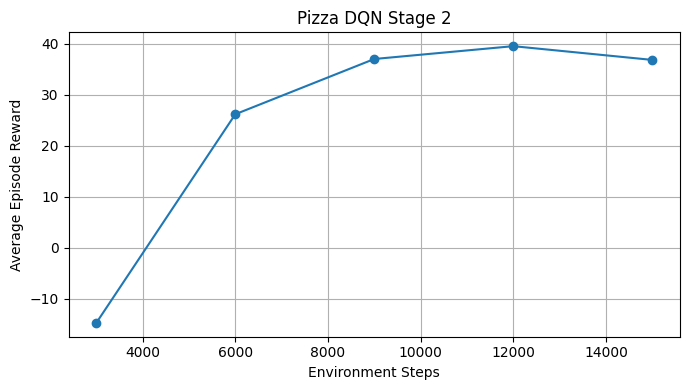

In [ ]:
if __name__ == "__main__":
    torch.set_num_threads(1)
    agent, test_steps, test_scores = train_dqn(FinalKitchenEnv)

    plt.figure(figsize=(7, 4))
    plt.plot(test_steps, test_scores, marker="o")
    plt.title("Pizza DQN Stage 2")
    plt.xlabel("Environment Steps")
    plt.ylabel("Average Episode Reward")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [ ]:
def show_dqn_play(agent, episodes=5, seed=101):
    env = KitchenDQNObservation(FinalKitchenEnv())
    raw_env = env.unwrapped
    saved_random_state = random.getstate()
    random.seed(seed)
    try:
        for episode in range(episodes):
            state, _ = env.reset()
            total_reward = 0.0
            step = 0
            print(f"\n========== 게임 {episode + 1} ==========")
            while True:
                step += 1
                print(f"\n[{step}스텝] 상태",
                      np.rint(state * raw_env.scale).astype(int).tolist())
                with torch.no_grad():
                    tensor = torch.as_tensor(
                        state, dtype=torch.float32, device=agent.device
                    ).unsqueeze(0)
                    values = agent.q_net(tensor)[0].cpu().tolist()
                action = int(np.argmax(values))
                print("Q값", {name: round(value, 2)
                              for name, value in zip(raw_env.action_names, values)})
                print("선택", raw_env.action_names[action])
                state, reward, terminated, truncated, info = env.step(action)
                print(f"보상 {reward:.2f}, 서빙 성공 {info['served']}건, "
                      f"만료 {info['expired']}건, 잘못된 서빙 {info['wrong_serve']}건")
                total_reward += reward
                if terminated or truncated:
                    print(f"총 보상 {total_reward:.2f}")
                    break
    finally:
        env.close()
        random.setstate(saved_random_state)

show_dqn_play(agent)


========== 게임 1 ==========

[1스텝] 상태 [0, 0, 0, 1, 14, 2, 13, 1, 16, 1, 15]
Q값 {'대기': 65.61, '도우': 70.37, '치즈': 62.7, '페퍼로니': 63.89, '서빙': 52.03}
선택 도우
보상 -0.10, 서빙 성공 0건, 만료 0건, 잘못된 서빙 0건

[2스텝] 상태 [1, 0, 0, 1, 13, 2, 12, 1, 15, 1, 14]
Q값 {'대기': 64.61, '도우': 62.64, '치즈': 70.07, '페퍼로니': 63.0, '서빙': 46.35}
선택 치즈
보상 -0.10, 서빙 성공 0건, 만료 0건, 잘못된 서빙 0건

[3스텝] 상태 [1, 1, 0, 1, 12, 2, 11, 1, 14, 1, 13]
Q값 {'대기': 64.67, '도우': 61.69, '치즈': 62.9, '페퍼로니': 67.15, '서빙': 71.89}
선택 서빙
보상 19.90, 서빙 성공 1건, 만료 0건, 잘못된 서빙 0건

[4스텝] 상태 [0, 0, 0, 0, 0, 2, 10, 1, 13, 1, 12]
Q값 {'대기': 48.08, '도우': 52.79, '치즈': 46.08, '페퍼로니': 46.2, '서빙': 34.42}
선택 도우
보상 -0.10, 서빙 성공 0건, 만료 0건, 잘못된 서빙 0건

[5스텝] 상태 [1, 0, 0, 0, 0, 2, 9, 1, 12, 1, 11]
Q값 {'대기': 45.55, '도우': 43.51, '치즈': 53.34, '페퍼로니': 45.12, '서빙': 24.58}
선택 치즈
보상 -0.10, 서빙 성공 0건, 만료 0건, 잘못된 서빙 0건

[6스텝] 상태 [1, 1, 0, 0, 0, 2, 8, 1, 11, 1, 10]
Q값 {'대기': 45.92, '도우': 43.66, '치즈': 43.91, '페퍼로니': 46.24, '서빙': 54.64}
선택 서빙
보상 19.90, 서빙 성공 1건, 만료 0건, 잘못된 서빙 0건

[7스텝] 상태